In [1]:
# =============================================
#                   IMPORT
# =============================================
from    preProcessingDataCrusher            import PreProcessData
from    utility.matpilotDraw                import MatPlot 
from    utility.plotlyDraw                 import PlotlyDraw
from    tqdm                               import tqdm
from    datetime                           import datetime
from    prettytable                        import PrettyTable
import  plotly.graph_objects                as go
import  numpy                               as np 
import  pandas                              as pd
import  matplotlib.pyplot                   as plt
import  os, warnings
import  random
import  json

np.random.seed(1)
random.seed(1)

# ====================================
# Config
# ------------------------------------
with open('utility/modelConfig.json', 'r') as configFile:
    config = json.load(configFile)
myConfig   = config["crusher"]



In [2]:
matPlot    = MatPlot() 
plotly     = PlotlyDraw()
preData    = PreProcessData(config=myConfig)

In [3]:
outputDir                               = os.path.expanduser(myConfig["dataDir"])

cr1, cr2, cv2                           = preData.loadH5File(dir= outputDir, name = "data/InterpolatedWholeConsistentData", keys = ["cr1", "cr2", "cv2"])                           # Load the data from critical file

withHourCr1                             = preData.addHours(cr1.copy())
withHourCr2                             = preData.addHours(cr2.copy())
withHourCv2                             = preData.addHours(cv2.copy())

withIDResults, mofOrder, shutdownMask   = preData.attachIDPerEvent(df = [withHourCr1,withHourCr2,withHourCv2])



handledValues           = preData.crusher1Value + preData.addEfficiencyCr1 + preData.addedManipulatedCr1
addedData               = preData.addition_var(withIDResults["cr1"].copy()) 
# -----------------------------
# Normalize
normalizedCr1           = preData.normalizeBuilinFunction(addedData,      headline = handledValues)  


Process:74675||2025-03-14 15:08:21,784-INFO [preProcessingDataCrusher.py:loadH5File():669]:Loading H5 file ...
Process:74675||2025-03-14 15:08:23,072-INFO [preProcessingDataCrusher.py:loadH5File():675]:Finish loading data from files ...
Process:74675||2025-03-14 15:08:23,127-INFO [preProcessingDataCrusher.py:addHours():702]:Add hour to data
Process:74675||2025-03-14 15:08:23,199-INFO [preProcessingDataCrusher.py:addHours():702]:Add hour to data
Process:74675||2025-03-14 15:08:23,271-INFO [preProcessingDataCrusher.py:addHours():702]:Add hour to data
Process:74675||2025-03-14 15:08:23,325-INFO [preProcessingDataCrusher.py:attachIDPerEvent():434]:Attaching ID into trajectories
Process:74675||2025-03-14 15:08:41,644-INFO [preProcessingDataCrusher.py:normalizeBuilinFunction():1586]:Normalizing the data ....


47514      791.900
74932     1248.867
113873    1897.900
115243    1920.733
155362    2589.383
Name: hours, dtype: float64


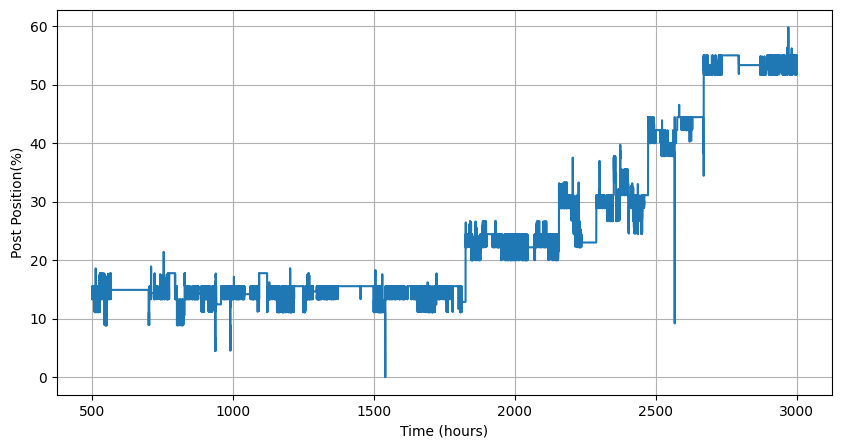

In [5]:
comp        = withIDResults["cr1"]

time_filtered_df    = comp[(comp['hours'] >= 500) & (comp['hours'] <= 3000)]
transition_indices  = np.where(time_filtered_df["trajIDWithM"].diff().fillna(0) != 0)[0]


# indices             = time_filtered_df['hours'][transition_indices]

indicesEvent         = time_filtered_df.iloc[transition_indices]["hours"]

print(indicesEvent)

# for idxValue in preData.crusher1Value:
matPlot.draw2D(xCoor    =   time_filtered_df["hours"], 
                    yCoor    =   time_filtered_df["posicion_poste(%)"], 
                    yLabel   =   "Post Position(%)",
                    xLabel  = "Time (hours)",
                    title= None
                    )

# for idxValue in preData.crusher1Value:
#     matPlot.draw2D(xCoor    =   time_filtered_df["hours"], 
#                             yCoor    =   time_filtered_df[idxValue]["posicion_poste(%)"], 
#                             yLabel   =   idxValue,
#                             events    =   indicesEvent)

47514      791.900
74932     1248.867
113873    1897.900
115243    1920.733
155362    2589.383
Name: hours, dtype: float64


/home/duc-an/Documents/2ndRealDataJournal/utility/matpilotDraw.py:51: FutureWarning: The behavior of `series[i:j]` with an integer-dtype index is deprecated. In a future version, this will be treated as *label-based* indexing, consistent with e.g. `series[i]` lookups. To retain the old behavior, use `series.iloc[i:j]`. To get the future behavior, use `series.loc[i:j]`.
  plt.plot(xCoor[start_idx:event_idx], yCoor[start_idx:event_idx], color=colors[i % len(colors)], label=f'Trajectory {i+1}')
/home/duc-an/Documents/2ndRealDataJournal/utility/matpilotDraw.py:60: FutureWarning: The behavior of `series[i:j]` with an integer-dtype index is deprecated. In a future version, this will be treated as *label-based* indexing, consistent with e.g. `series[i]` lookups. To retain the old behavior, use `series.iloc[i:j]`. To get the future behavior, use `series.loc[i:j]`.
  plt.plot(xCoor[start_idx:], yCoor[start_idx:], color=colors[len(events) % len(colors)], label=f'Trajectory {len(events) + 1}')


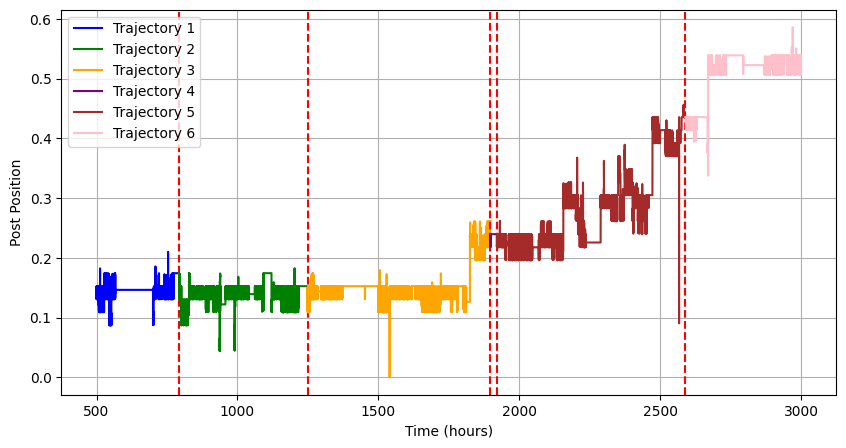

In [7]:
# indices         = cr1[(cr1['hours'] > 1961) & (cr1['hours'] < 3036)].index

comp        = normalizedCr1

time_filtered_df    = comp[(comp['hours'] >= 500) & (comp['hours'] <= 3000)]
transition_indices  = np.where(time_filtered_df["trajIDWithM"].diff().fillna(0) != 0)[0]


# indices             = time_filtered_df['hours'][transition_indices]

indicesEvent         = time_filtered_df.iloc[transition_indices]["hours"]

print(indicesEvent)

matPlot.draw2DWithEvent(xCoor    =   time_filtered_df["hours"], 
                        yCoor    =   time_filtered_df["posicion_poste(%)"], 
                        yLabel   =   "Post Position",
                         xLabel  = "Time (hours)",
                         title= None,
                        events   =   indicesEvent)

# for idxValue in preData.crusher1Value:
#     matPlot.draw2DWithEvent(xCoor    =   time_filtered_df["hours"], 
#                             yCoor    =   time_filtered_df[idxValue]["posicion_poste(%)"], 
#                             yLabel   =   idxValue,
#                             events    =   indicesEvent)
    

In [ ]:
# -----------------------------
# Normalize
normalizedCr1           = preData.normalizeBuilinFunction(withIDCr1, headline = preData.crusher1Value)  
normalizedCr2           = preData.normalizeBuilinFunction(withIDCr2, headline = preData.crusher2Value)  
normalizedCv2           = preData.normalizeBuilinFunction(withIDCv2, headline = preData.conveyorValue)  

# -----------------------------
# Add the Cycle and RUL to 
# each component
withTimeDataCr1         = preData.addCycleAndRul(normalizedCr1)                        # Add the time to the data
cycleCr1                = withTimeDataCr1["cycle"]
rulCr1                  = withTimeDataCr1["rul"]

withTimeDataCr2         = preData.addCycleAndRul(normalizedCr2)                        # Add the time to the data
withTimeDataCv2         = preData.addCycleAndRul(normalizedCv2)                        # Add the time to the data

# -----------------------------
# Add the cycle and RUL of system
systemData                  = pd.DataFrame()
systemData['tiempo']        = withTimeDataCr1["tiempo"]
systemData['trajectoryID']  = IdSys
withTimeDataSys             = preData.addCycleAndRul(systemData)


NameError: name 'withIDCr1' is not defined

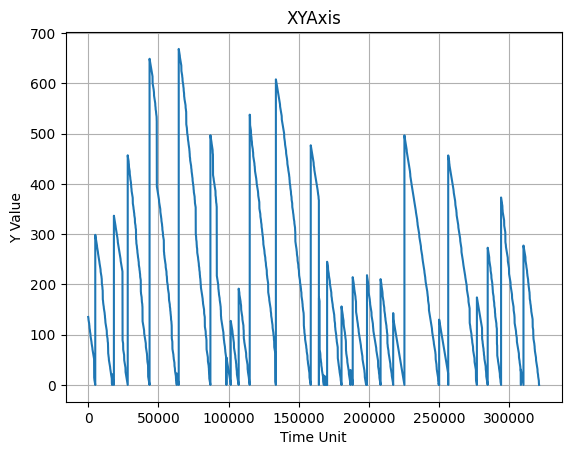

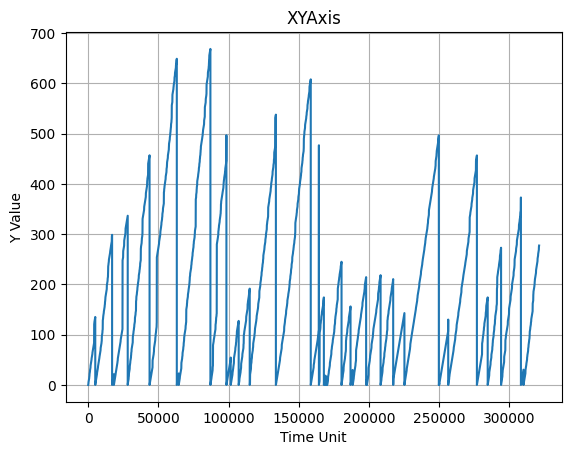

In [ ]:
matPlot.draw1D(rulCr1)
matPlot.draw1D(cycleCr1)

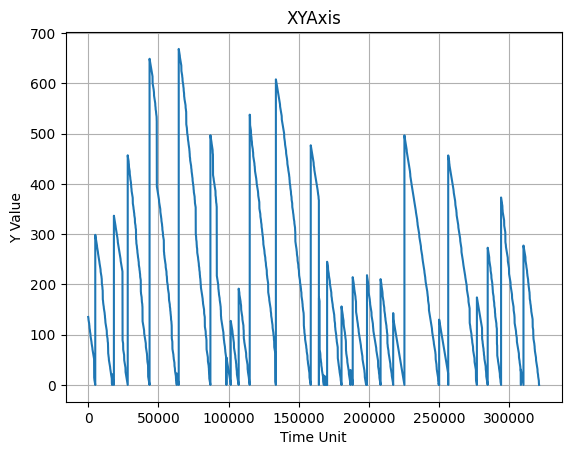

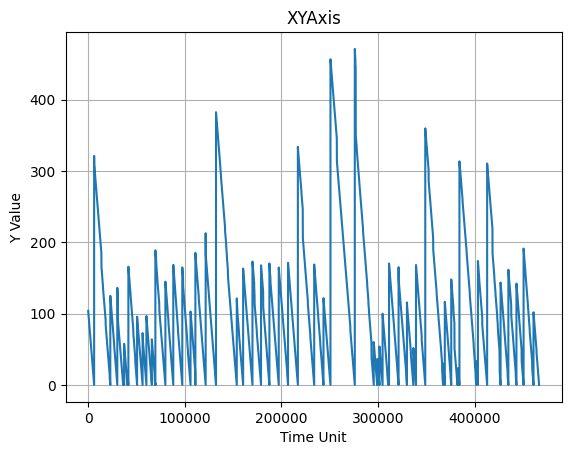

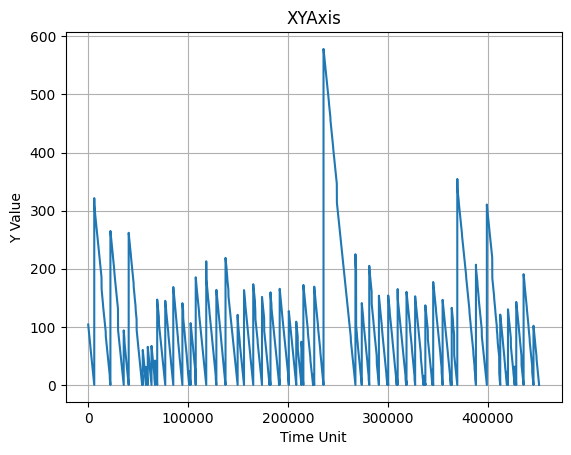

In [ ]:
matPlot.draw1D(withTimeDataCr1["rul"])
matPlot.draw1D(withTimeDataCr2["rul"])
matPlot.draw1D(withTimeDataCv2["rul"])


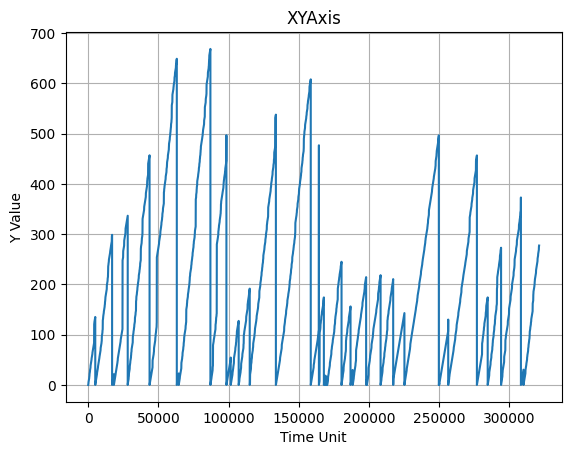

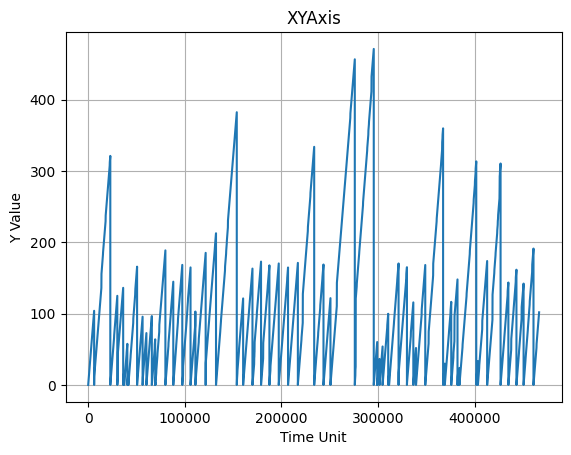

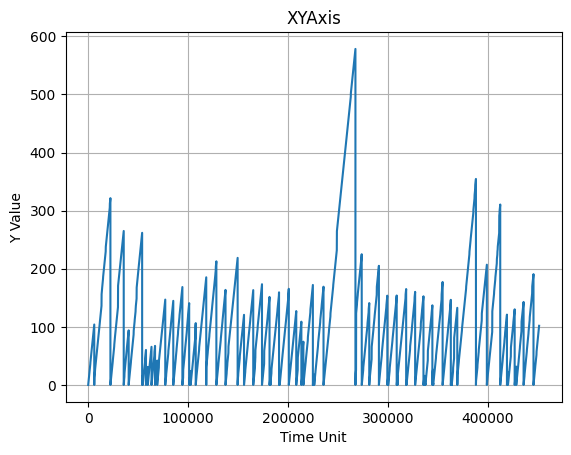

In [ ]:
matPlot.draw1D(withTimeDataCr1["cycle"])
matPlot.draw1D(withTimeDataCr2["cycle"])
matPlot.draw1D(withTimeDataCv2["cycle"])

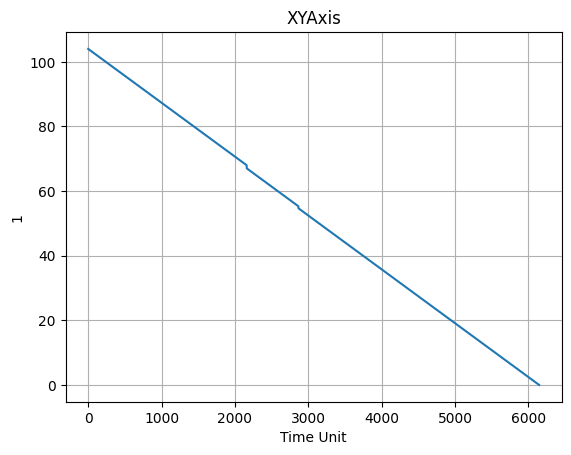

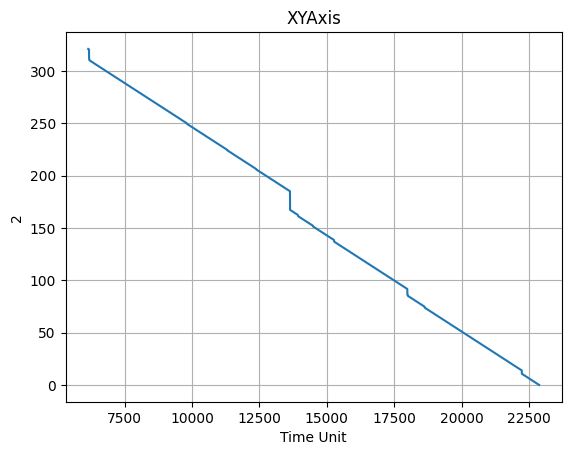

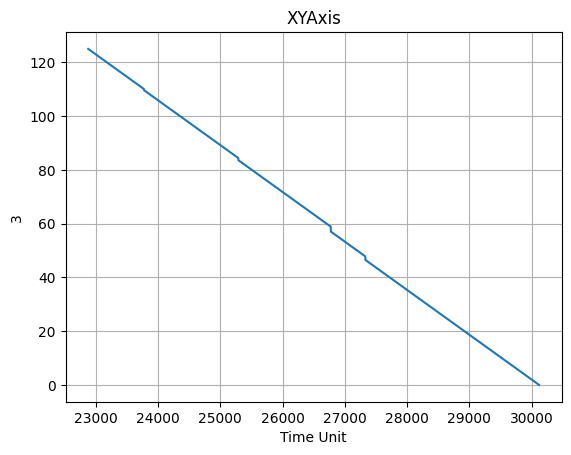

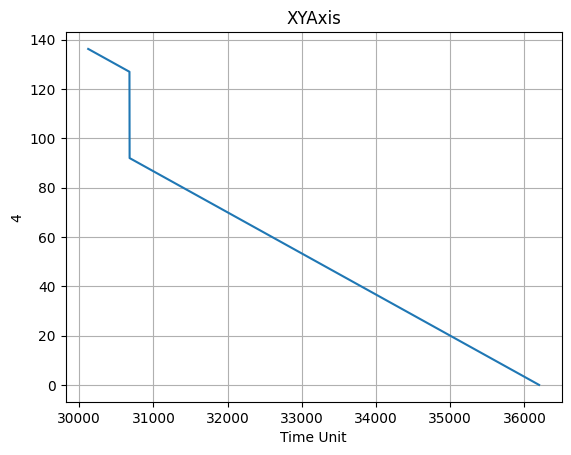

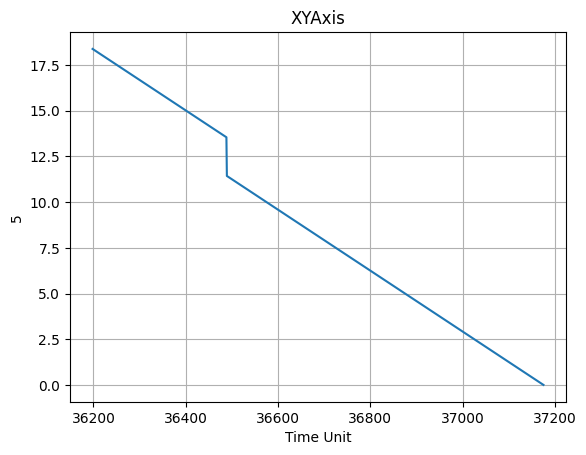

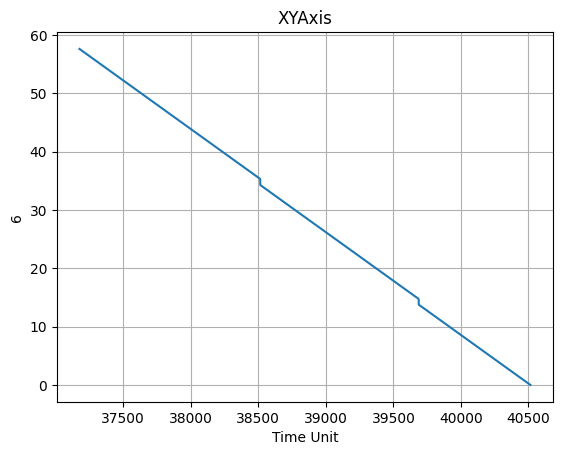

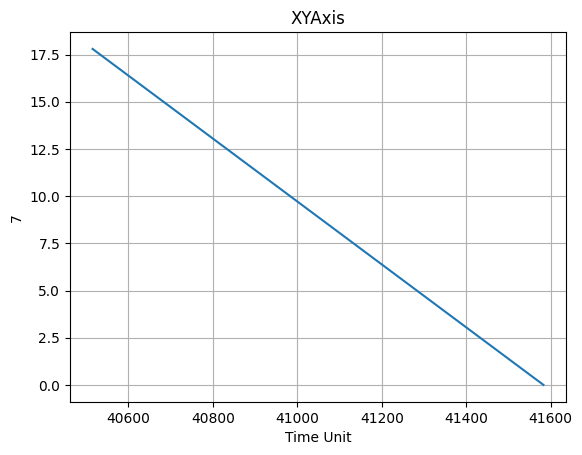

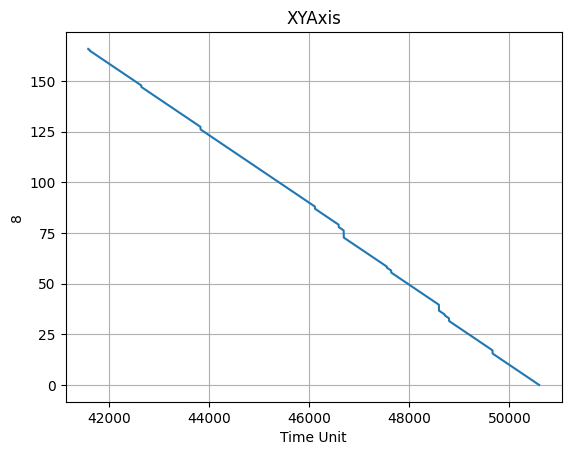

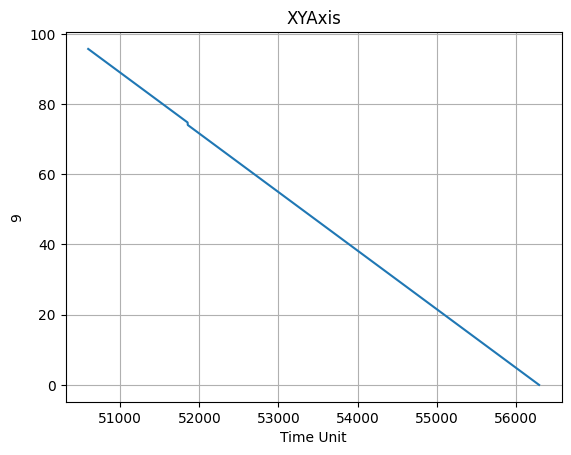

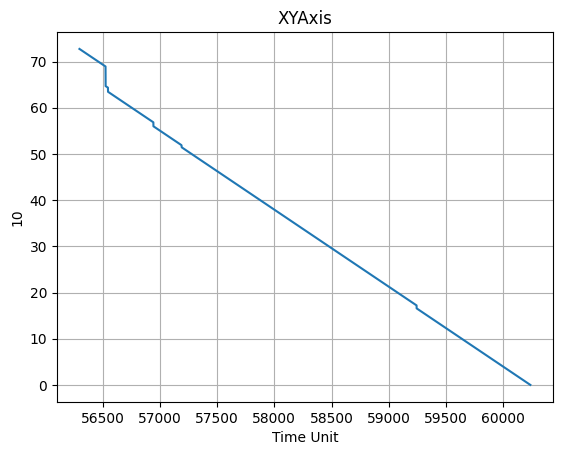

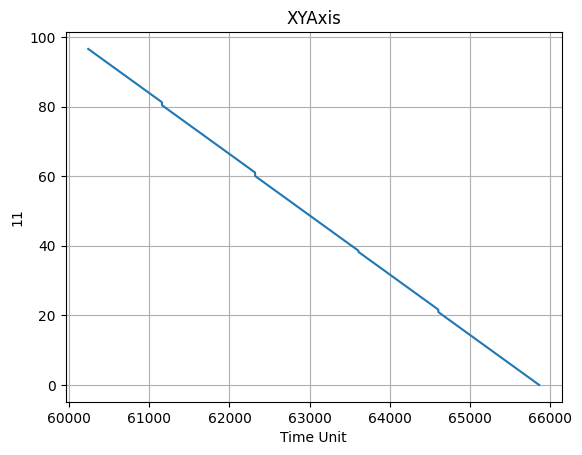

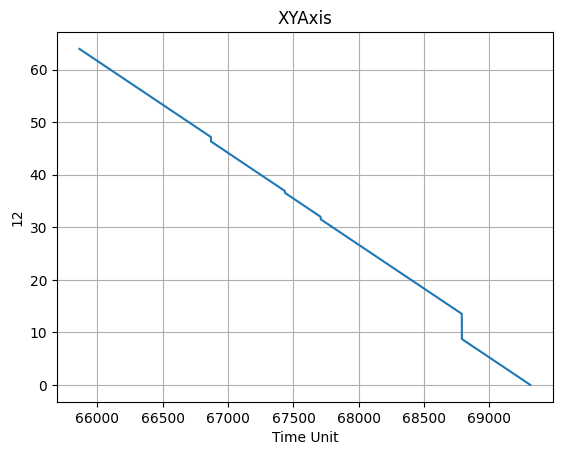

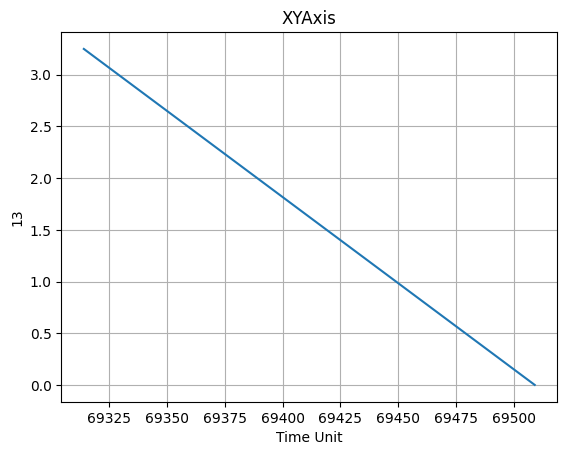

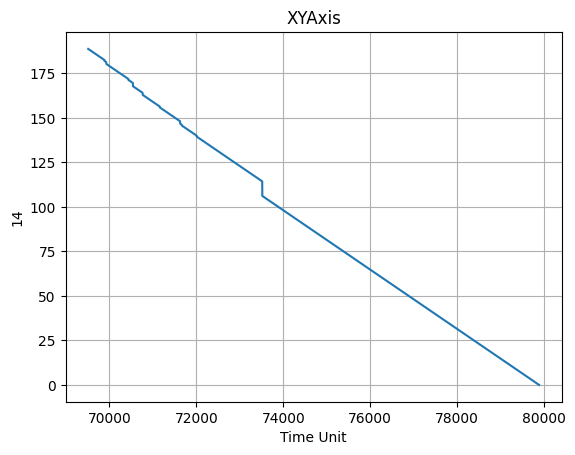

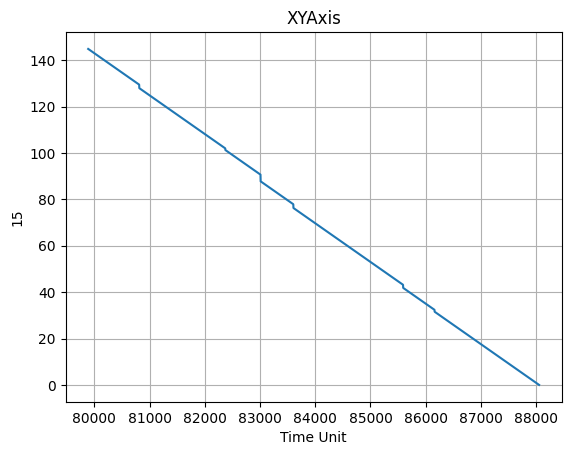

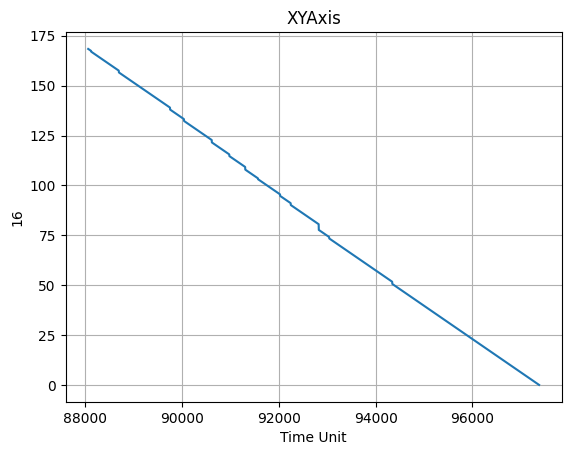

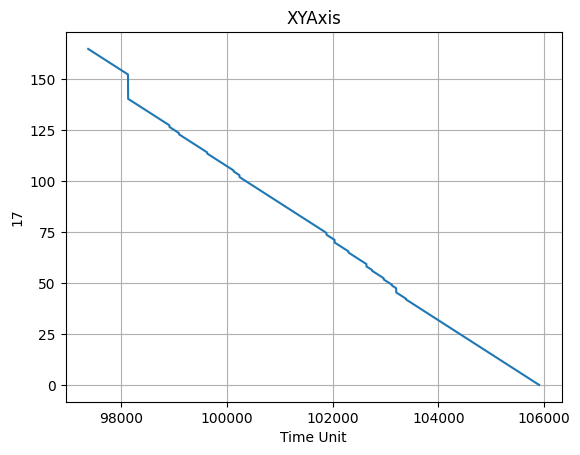

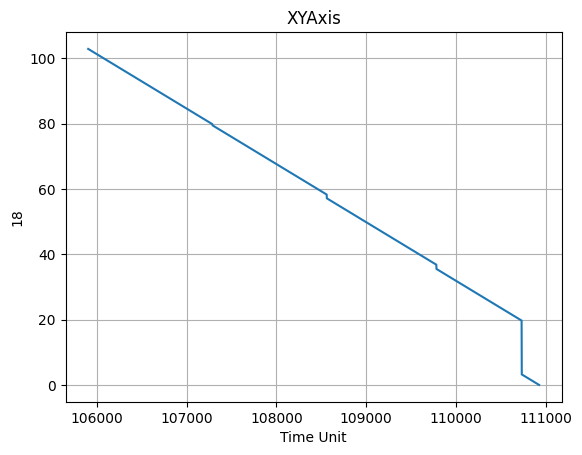

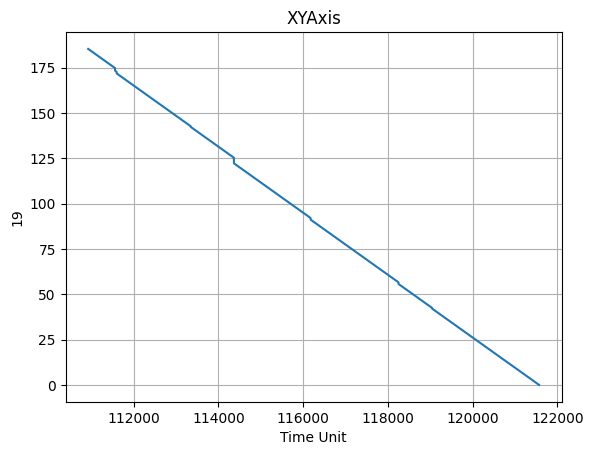

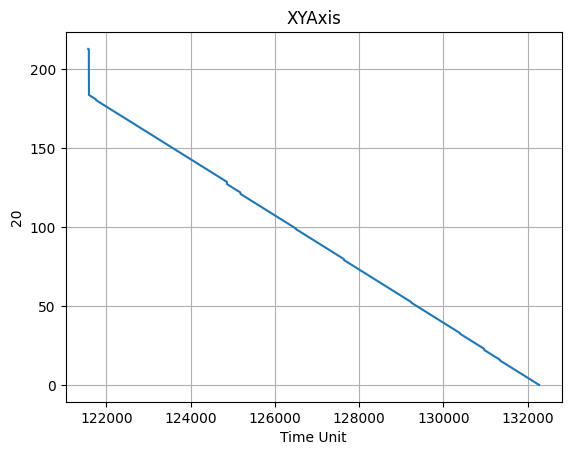

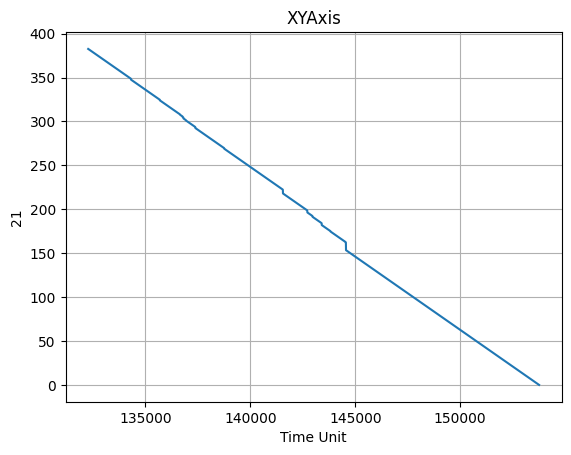

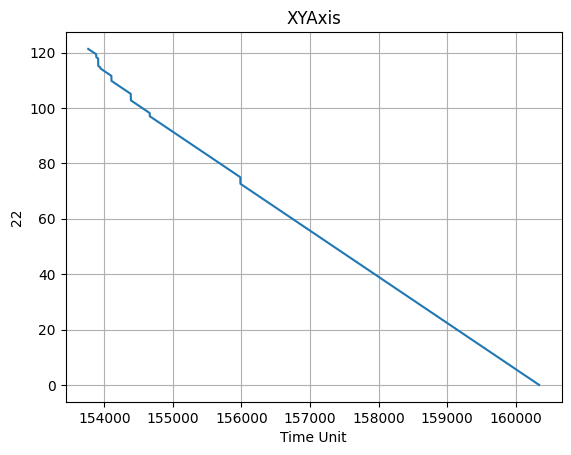

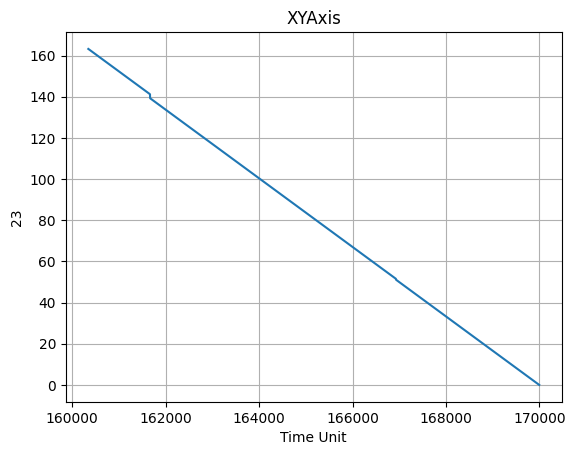

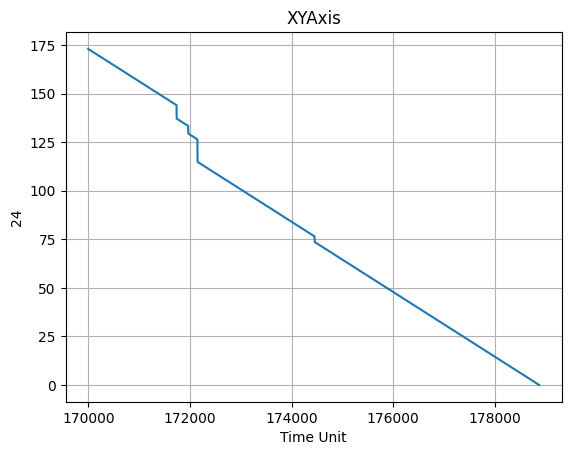

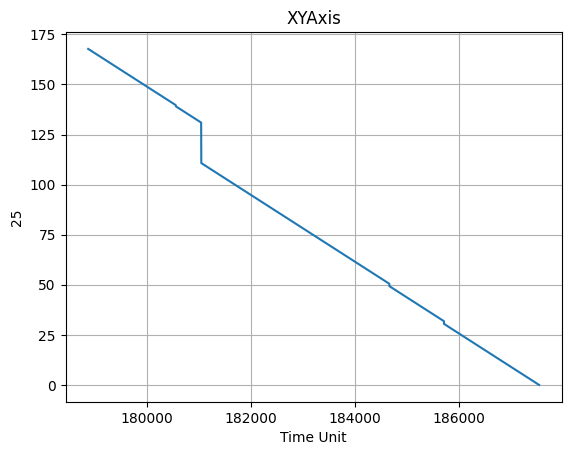

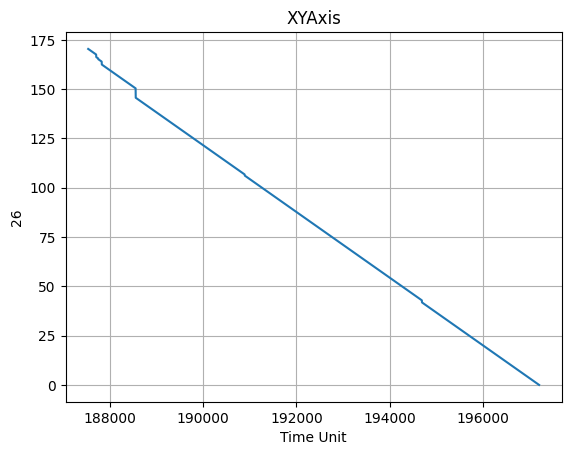

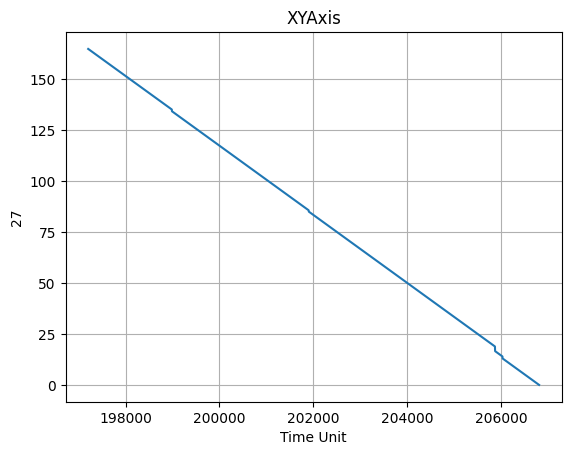

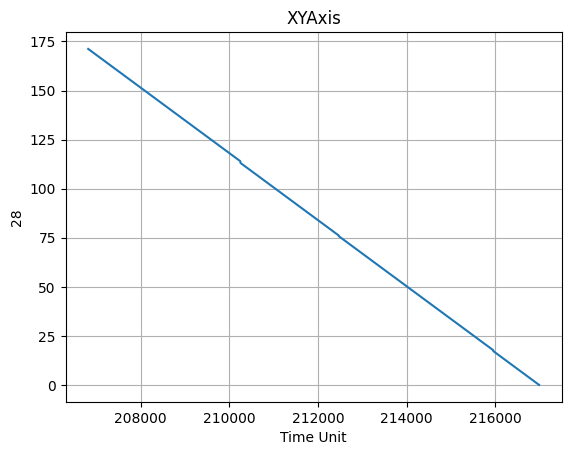

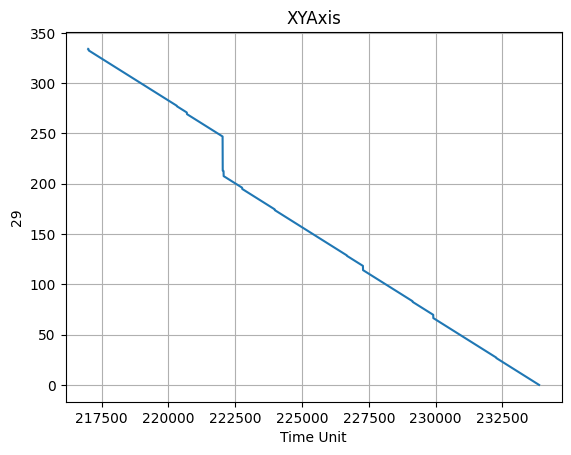

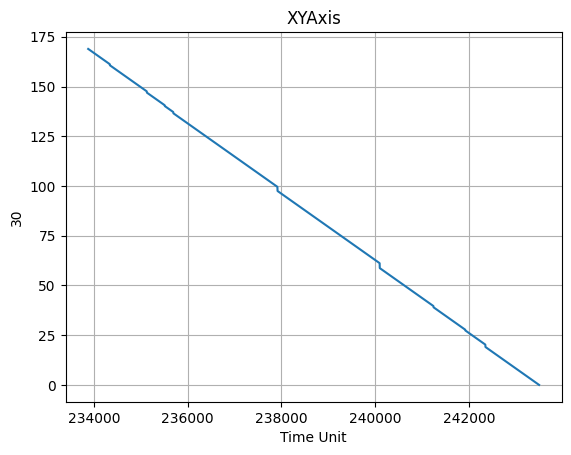

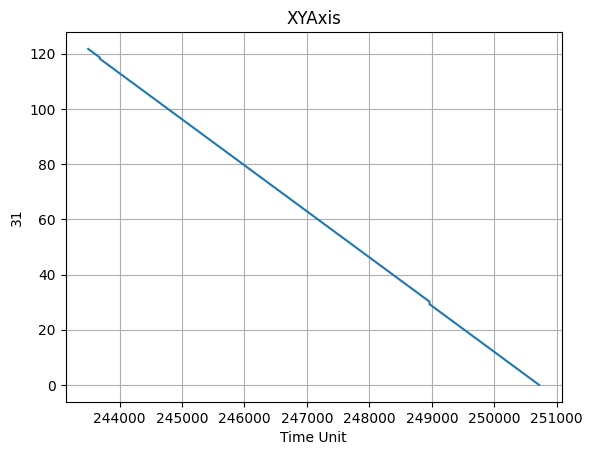

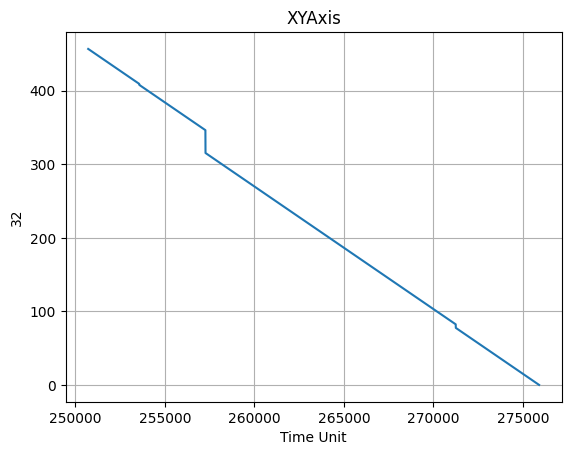

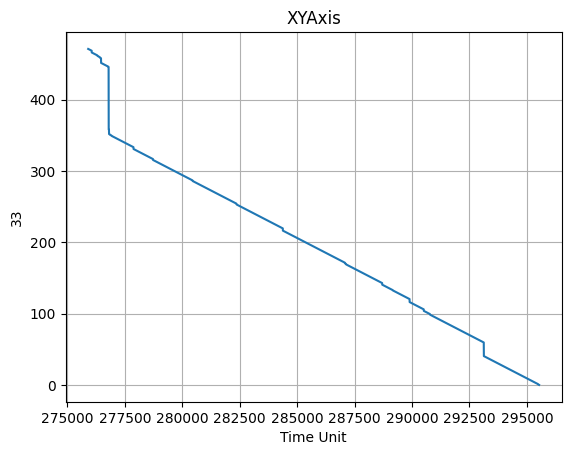

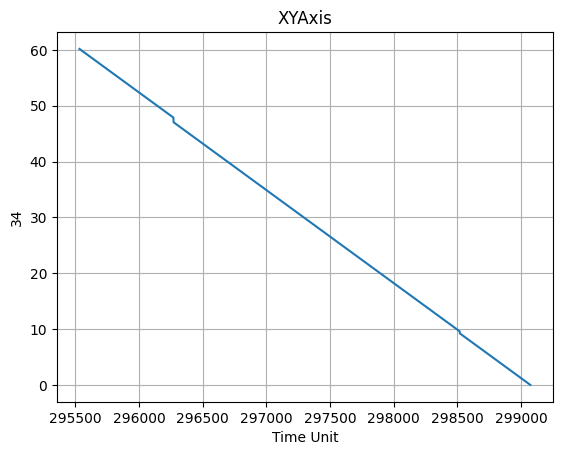

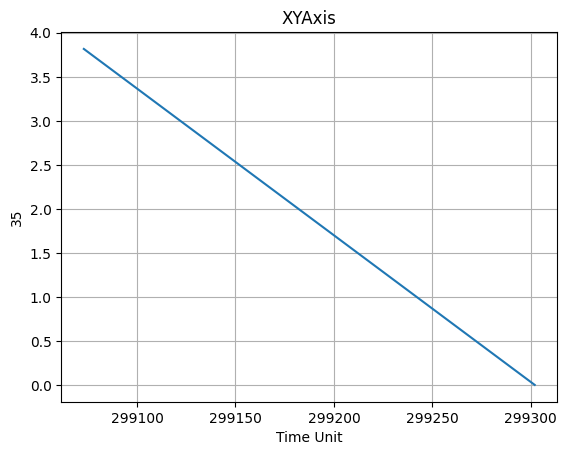

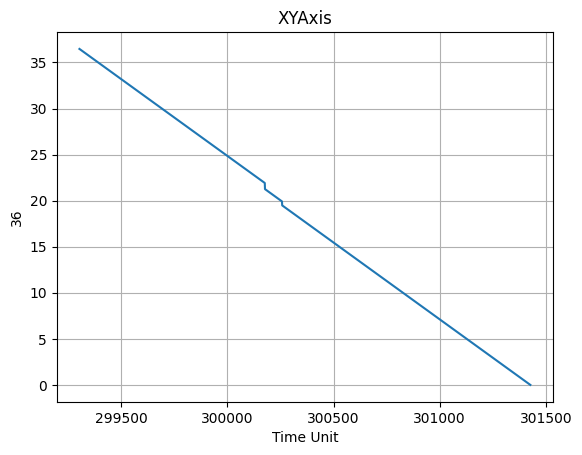

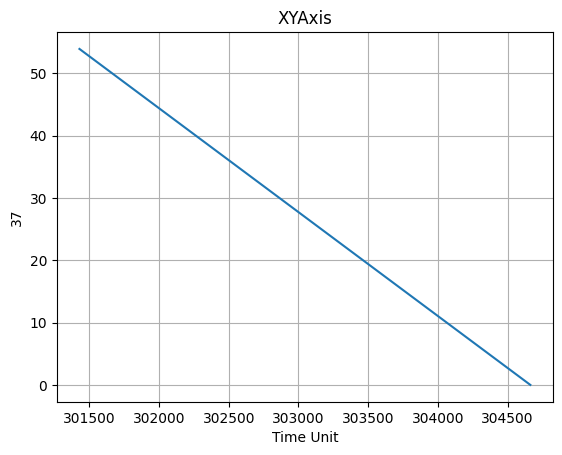

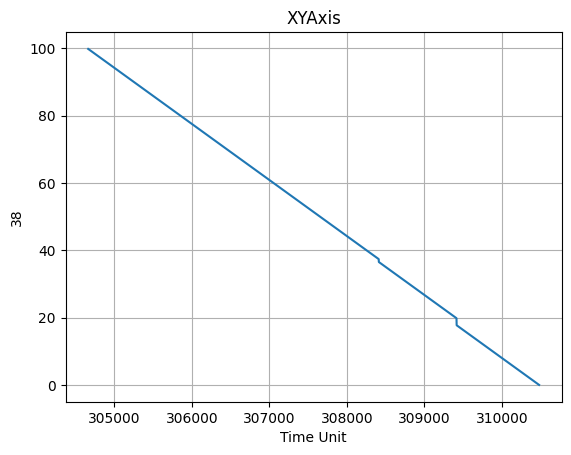

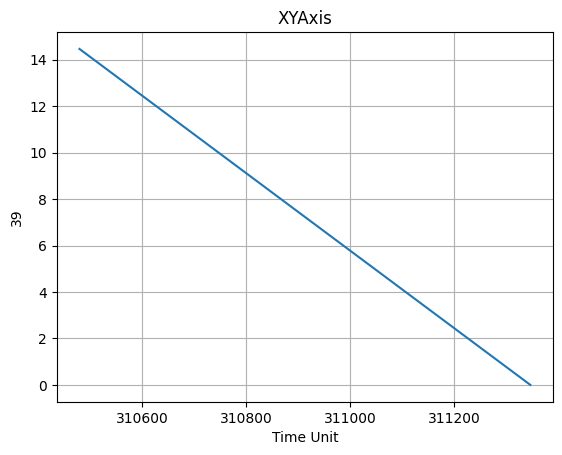

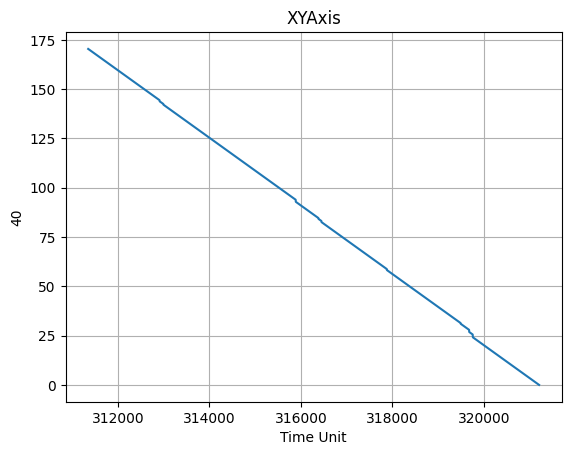

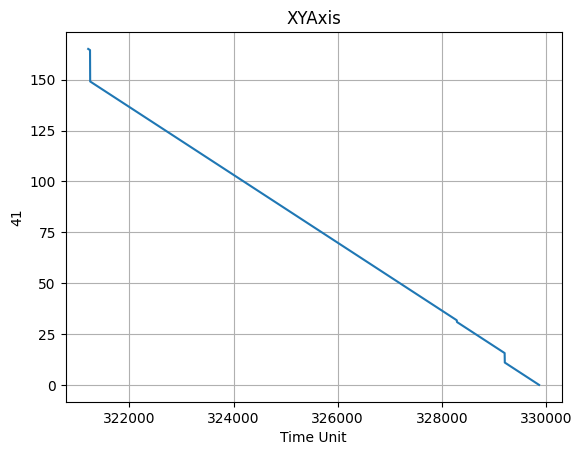

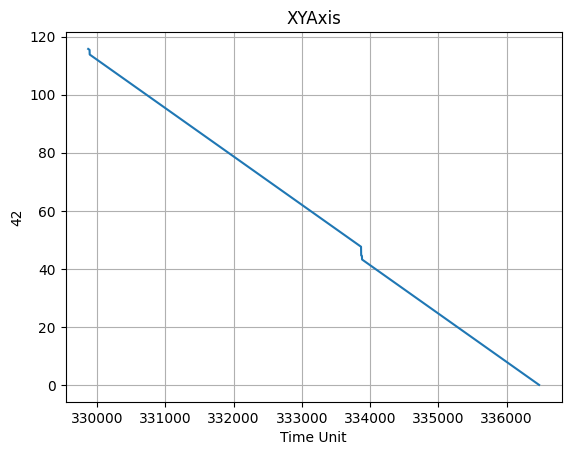

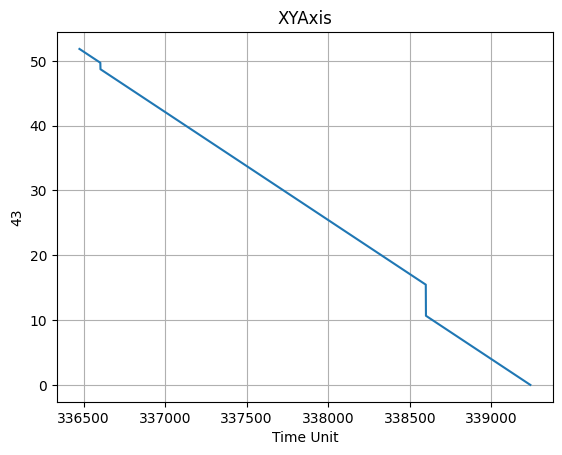

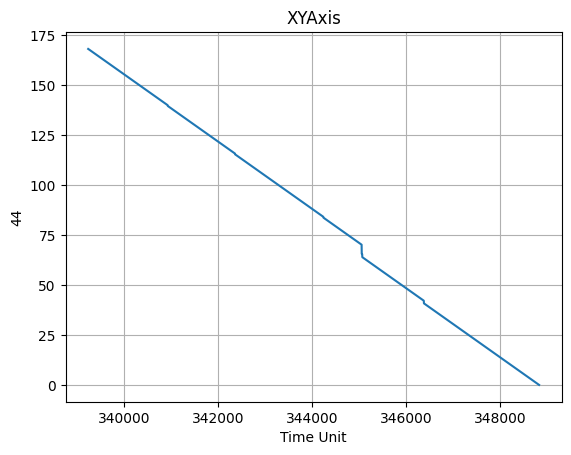

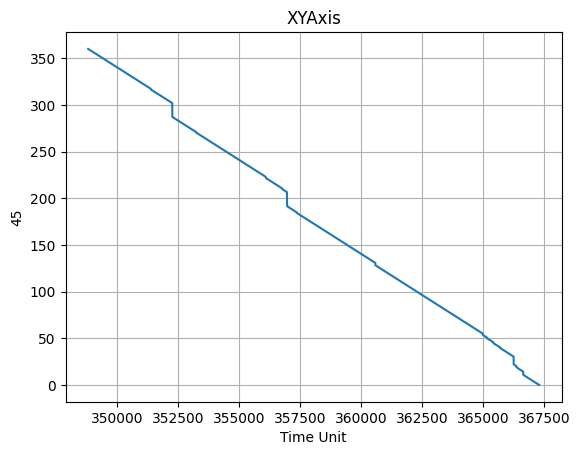

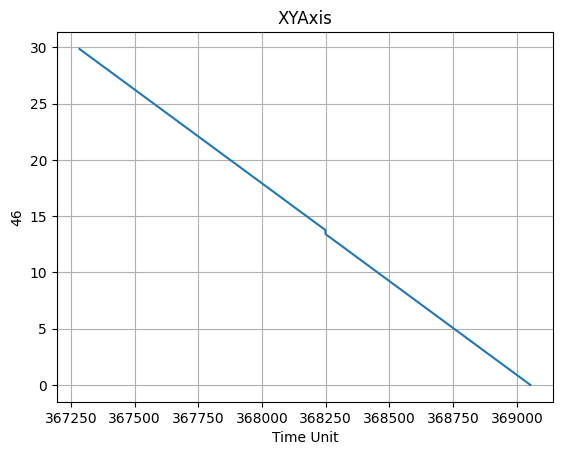

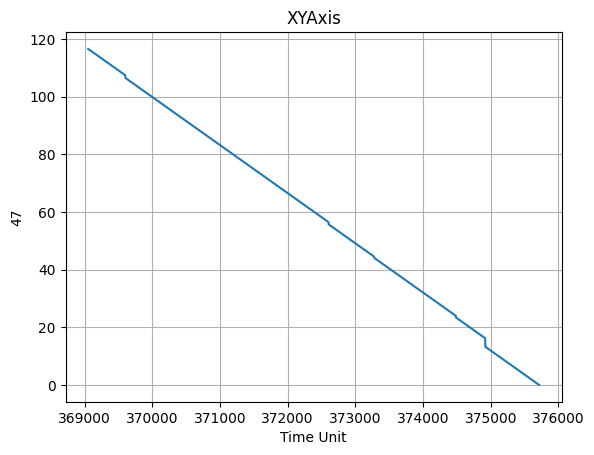

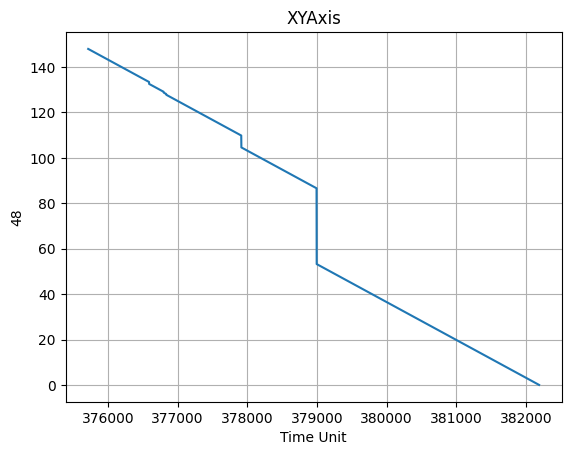

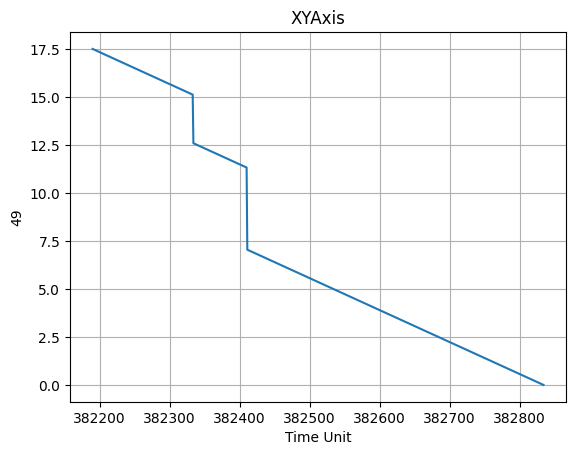

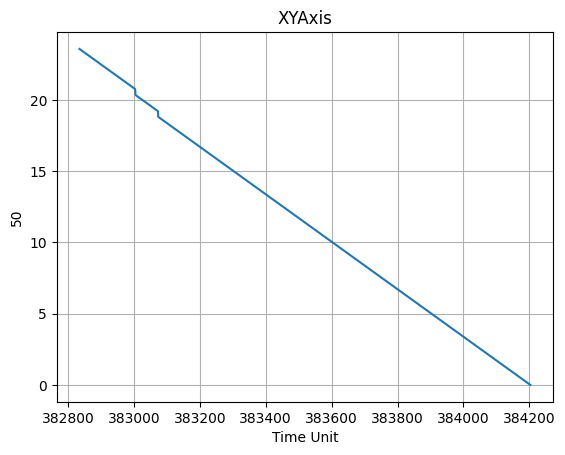

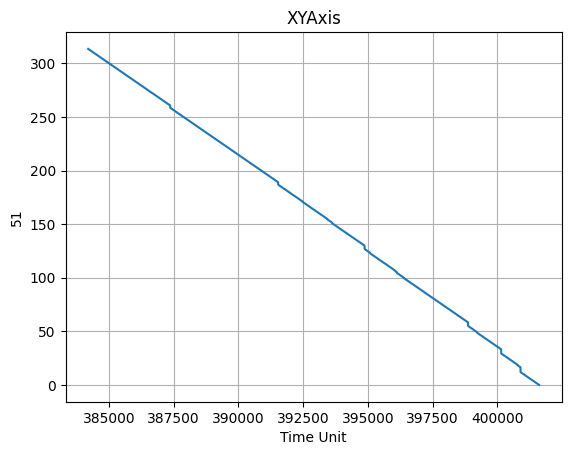

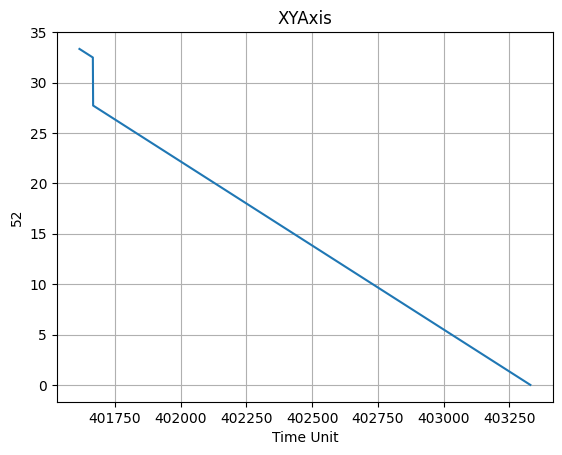

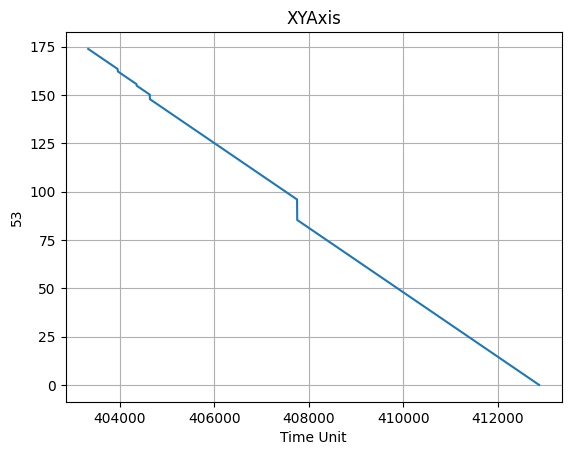

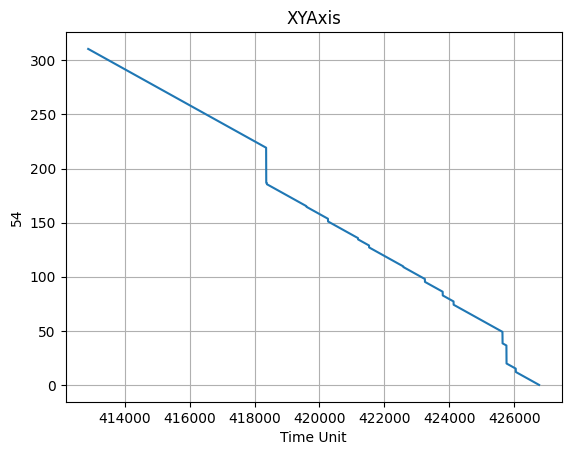

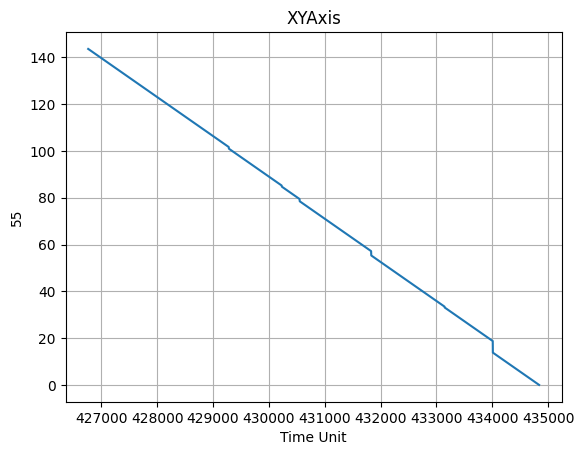

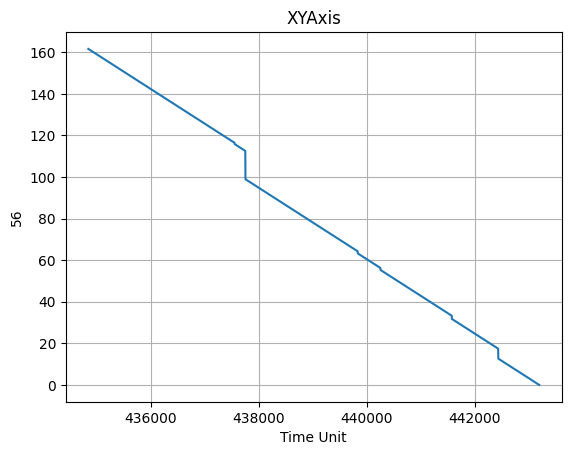

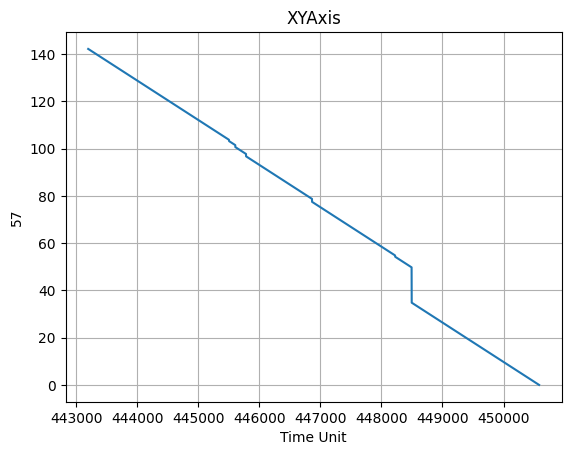

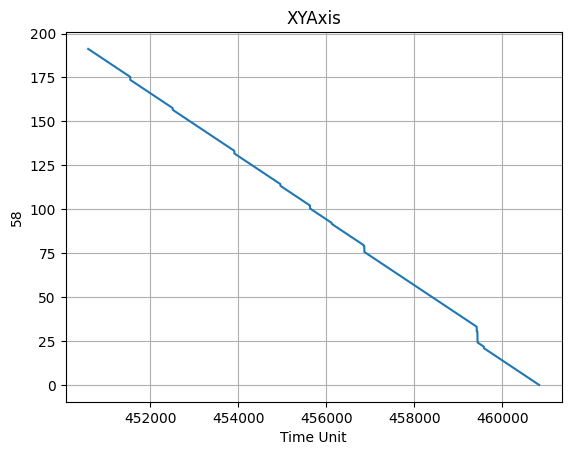

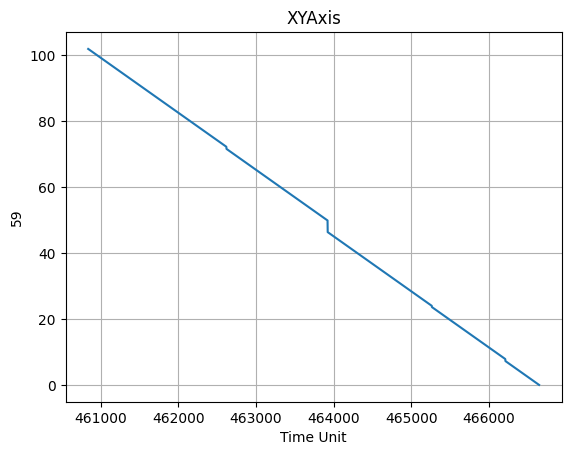

In [ ]:
for idx in range(withIDCr2["trajectoryID"].values.max()):
    data = withTimeDataCr2["rul"][withTimeDataCr2["trajectoryID"] == (idx + 1)]
    matPlot.draw1D(data, yLabel= (idx + 1))